# 01 · Exploración de datos
**Caso:** Sistema de recomendación de productos · Nexus Retail SpA

**Objetivo de este notebook:** conocer los cuatro datasets, medir su calidad y verificar que alcanzan para construir la variable objetivo del recomendador (`compra` de un SKU por un usuario).

Este notebook **solo explora**: no modifica los archivos originales ni guarda datos limpios. Las correcciones se aplican sobre copias en memoria y se documentan para el siguiente notebook.

**Contenido**
1. Configuración y carga
2. Visión general
3. Calidad de datos por dataset (productos, transacciones, usuarios, clickstream)
4. Integridad entre datasets
5. Análisis exploratorio sobre datos depurados
6. Viabilidad de la variable objetivo
7. Resumen y decisiones para el modelado

## 1. Configuración y carga

In [3]:
import os
import re
import unicodedata
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")


DATA_DIR = Path("../datos/crudos")

def leer_csv(nombre):
    """Lee el CSV cuyo nombre termina en `nombre`.csv (tolera prefijos)."""
    candidatos = sorted(DATA_DIR.glob(f"*{nombre}.csv"))
    if not candidatos:
        raise FileNotFoundError(f"No se encontró '{nombre}.csv' en {DATA_DIR.resolve()}")
    return pd.read_csv(candidatos[0])


productos = leer_csv("productos")
transacciones = leer_csv("transacciones")
usuarios = leer_csv("usuarios")
clickstream = leer_csv("clickstream")

datasets = {
    "productos": productos,
    "transacciones": transacciones,
    "usuarios": usuarios,
    "clickstream": clickstream,
}

### Funciones auxiliares

In [4]:
def norm_texto(s):
    """Minúsculas, sin tildes y sin espacios sobrantes. Conserva los nulos."""
    def f(x):
        if pd.isna(x):
            return np.nan
        x = unicodedata.normalize("NFKD", str(x))
        x = "".join(c for c in x if not unicodedata.combining(c))
        return x.strip().lower()
    return s.map(f)


def parse_fecha(s):
    """Convierte fechas con formatos mezclados (ISO, ISO con Z/offset, dd-mm-yyyy, dd/mm/yyyy).
    Devuelve datetime sin zona horaria; lo que no se pueda interpretar queda como NaT."""
    s = s.astype("string")
    out = pd.to_datetime(s, format="ISO8601", errors="coerce", utc=True)
    resto = out.isna() & s.notna()
    if resto.any():
        alt = pd.to_datetime(s[resto], format="mixed", dayfirst=True, errors="coerce", utc=True)
        out = out.where(~resto, alt)
    return out.dt.tz_convert(None)


def limpiar_monto(s):
    """Convierte montos escritos como '$22.743' (punto = separador de miles) o como número normal.
    Textos no numéricos (p. ej. 'ERROR') quedan como NaN."""
    t = s.astype("string").str.strip()
    con_signo = t.str.startswith("$", na=False)
    t = t.where(~con_signo, t.str.replace("$", "", regex=False).str.replace(".", "", regex=False))
    return pd.to_numeric(t, errors="coerce")


def pct(a, b):
    return 100 * a / b if b else np.nan

## 2. Visión general

In [5]:
resumen = pd.DataFrame({
    nombre: {
        "filas": len(df),
        "columnas": df.shape[1],
        "filas duplicadas (exactas)": int(df.duplicated().sum()),
        "celdas nulas": int(df.isna().sum().sum()),
    }
    for nombre, df in datasets.items()
}).T
resumen

,filas,columnas,filas duplicadas (exactas),celdas nulas
productos,1531,9,31,227
transacciones,22187,11,186,9175
usuarios,4026,8,26,1487
clickstream,29340,9,263,46993


In [6]:
for nombre, df in datasets.items():
    print(f"\n=== {nombre} ===")
    nulos = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "nulos": df.isna().sum(),
        "% nulos": df.isna().mean() * 100,
        "únicos": df.nunique(),
    })
    display(nulos)
    display(df.head(3))


=== productos ===


,dtype,nulos,% nulos,únicos
sku,str,0,0.00,1500
nombre,str,27,1.76,867
categoria,str,0,0.00,20
marca,str,17,1.11,16
precio_lista,str,26,1.70,1412
costo,float64,157,10.25,1298
stock,str,0,0.00,247
activo,str,0,0.00,7
fecha_alta,str,0,0.00,1300


,sku,nombre,categoria,marca,precio_lista,costo,stock,activo,fecha_alta
0,NX-10637,Gigabyte Notebook X,Notebooks,Gigabyte,19666,"12,193.00",5,0,22-11-2024
1,NX-10785,Kingston Monitore Lite,Monitores,Kingston,21993,"13,636.00",-9,0,2024-01-29
2,NX-10647,Dell Rede V2,Redes,Dell,37619,"23,324.00",2,Si,2020-07-06



=== transacciones ===


,dtype,nulos,% nulos,únicos
pedido_id,str,0,0.00,17146
linea,int64,0,0.00,4
usuario_id,str,93,0.42,4224
sku,str,0,0.00,1201
fecha,str,0,0.00,19165
cantidad,int64,0,0.00,9
precio_unitario,str,440,1.98,17446
descuento,float64,8642,38.95,4884
total,int64,0,0.00,18753
canal,str,0,0.00,7


...

,dtype,nulos,% nulos,únicos
usuario_id,str,0,0.00,4000
fecha_registro,str,0,0.00,2833
region,str,0,0.00,33
comuna,str,304,7.55,18
canal_captacion,str,129,3.20,6
email_valido,object,180,4.47,2
acepta_marketing,float64,733,18.21,2
edad,float64,141,3.50,81


,usuario_id,fecha_registro,region,comuna,canal_captacion,email_valido,acepta_marketing,edad
0,U103808,2023-04-19,COQUIMBO,Antofagasta,organico,True,NaN,40.00
1,U103458,2022-05-03,Valparaiso,Iquique,organico,False,NaN,0.00
2,U103013,10/01/2022,Biobío,Temuco,pagado,NaN,0.00,48.00



=== clickstream ===


,dtype,nulos,% nulos,únicos
evento_id,str,0,0.00,29077
sesion_id,str,0,0.00,6000
usuario_id,str,17653,60.17,2411
timestamp,str,0,0.00,29060
tipo_evento,str,0,0.00,14
sku,str,6289,21.43,1439
termino_busqueda,str,23051,78.57,16
dispositivo,str,0,0.00,7
user_agent,str,0,0.00,11


,evento_id,sesion_id,usuario_id,timestamp,tipo_evento,sku,termino_busqueda,dispositivo,user_agent
0,E1005629,S201123,NaN,2025-03-22 00:56:38,vista,NX-11438,NaN,movil,Mozilla/5.0 (iPhone; CPU iPhone OS 17_5 like M...
1,E1004553,S200898,NaN,2026-05-09T16:19:23Z,vista,NX-11037,NaN,escritorio,Mozilla/5.0 (Linux; Android 14; SM-A546E) Appl...
2,E1023204,S204770,U100651,2025-10-08T06:37:26Z,busqueda,NaN,tarjeta de video,movil,Mozilla/5.0 (iPhone; CPU iPhone OS 17_5 like M...


## 3. Calidad de datos por dataset
### 3.1 Productos
Problemas esperados según el caso: categorías escritas a mano, precio 0 para productos en edición, stock inconsistente.

In [7]:
prod = productos.copy()

# Identificadores con espacios sobrantes (p. ej. "  NX-10265 ")
print(f"SKU con espacios sobrantes: {(prod['sku'] != prod['sku'].str.strip()).sum()}")
prod["sku"] = prod["sku"].str.strip()
print(f"Filas duplicadas exactas en productos: {prod.duplicated().sum()}  → se conservan {prod['sku'].nunique():,} SKU únicos")
prod = prod.drop_duplicates().reset_index(drop=True)

# Categorías: variantes de escritura
prod["categoria_norm"] = norm_texto(prod["categoria"])
print(f"Categorías distintas (crudo):      {prod['categoria'].nunique()}")
print(f"Categorías distintas (normalizado): {prod['categoria_norm'].nunique()}")
display(prod["categoria_norm"].value_counts().to_frame("skus"))

SKU con espacios sobrantes: 42
Filas duplicadas exactas en productos: 31  → se conservan 1,500 SKU únicos
Categorías distintas (crudo):      20
Categorías distintas (normalizado): 11


,skus
categoria_norm,
monitores,171
notebooks,162
redes,161
audio,156
perifericos,155
smartphones,154
gaming,145
almacenamiento,129
componentes,124


In [8]:
# Campo 'activo' con valores mezclados
print("Valores crudos de 'activo':", sorted(prod["activo"].astype(str).unique()))
mapa_bool = {"si": True, "true": True, "1": True, "no": False, "false": False, "0": False}
prod["activo_bool"] = norm_texto(prod["activo"].astype("string")).map(mapa_bool)
print("\nDespués de normalizar:")
display(prod["activo_bool"].value_counts(dropna=False).to_frame("skus"))

Valores crudos de 'activo': ['0', '1', 'No', 'Si', 'TRUE', 'false', 'true']

Después de normalizar:


,skus
activo_bool,
True,873
False,627


In [9]:
prod["fecha_alta_dt"] = parse_fecha(prod["fecha_alta"])

# precio_lista y stock llegan como texto ("$22.743", "ERROR"): se convierten a número
print(f"precio_lista escrito como '$...': {prod['precio_lista'].astype(str).str.startswith('$').sum()}")
print(f"stock con texto no numérico: {pd.to_numeric(prod['stock'], errors='coerce').isna().sum()}  → {sorted(prod.loc[pd.to_numeric(prod['stock'], errors='coerce').isna(), 'stock'].astype(str).unique())}")
prod["precio_lista"] = limpiar_monto(prod["precio_lista"])
prod["stock"] = pd.to_numeric(prod["stock"], errors="coerce")

chequeos = {
    "SKU duplicados": int(prod["sku"].duplicated().sum()),
    "precio_lista nulo": int(prod["precio_lista"].isna().sum()),
    "precio_lista = 0": int((prod["precio_lista"] == 0).sum()),
    "precio_lista < 0": int((prod["precio_lista"] < 0).sum()),
    "costo nulo": int(prod["costo"].isna().sum()),
    "costo > precio_lista": int((prod["costo"] > prod["precio_lista"]).sum()),
    "stock no numérico ('ERROR')": int(prod["stock"].isna().sum()),
    "stock < 0": int((prod["stock"] < 0).sum()),
    "stock = 0": int((prod["stock"] == 0).sum()),
    "nombre nulo": int(prod["nombre"].isna().sum()),
    "marca nula": int(prod["marca"].isna().sum()),
    "fecha_alta no interpretable": int(prod["fecha_alta_dt"].isna().sum()),
}
pd.Series(chequeos, name="casos").to_frame().assign(**{"% del catálogo": lambda d: d["casos"] / len(prod) * 100})

precio_lista escrito como '$...': 174
stock con texto no numérico: 16  → ['ERROR']


,casos,% del catálogo
SKU duplicados,0,0.00
precio_lista nulo,25,1.67
precio_lista = 0,37,2.47
precio_lista < 0,0,0.00
costo nulo,156,10.40
costo > precio_lista,65,4.33
stock no numérico ('ERROR'),16,1.07
stock < 0,36,2.40
stock = 0,292,19.47
nombre nulo,26,1.73


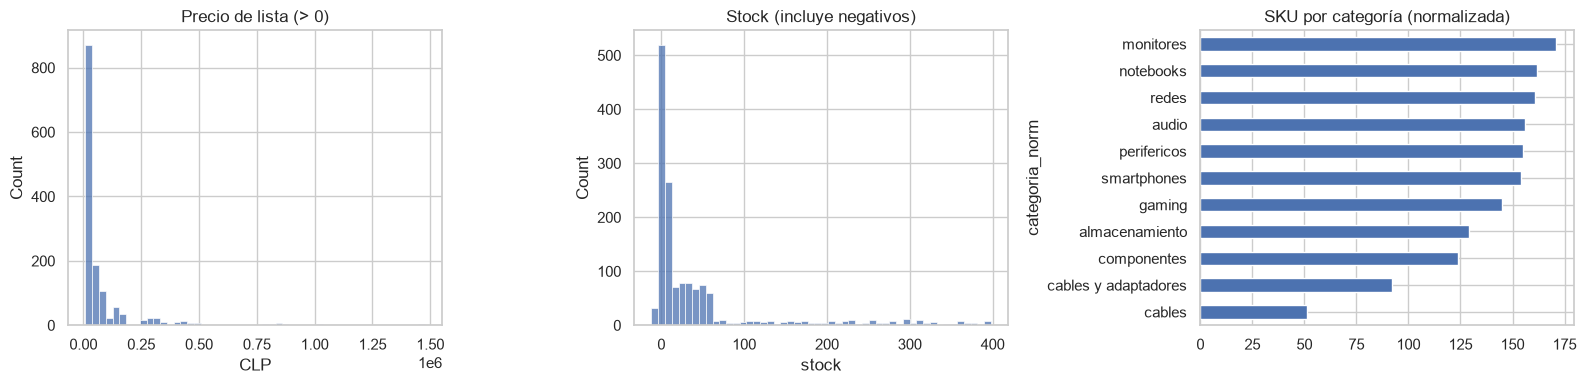

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(prod.loc[prod["precio_lista"] > 0, "precio_lista"], bins=50, ax=ax[0])
ax[0].set_title("Precio de lista (> 0)"); ax[0].set_xlabel("CLP")
sns.histplot(prod["stock"], bins=50, ax=ax[1])
ax[1].set_title("Stock (incluye negativos)")
prod["categoria_norm"].value_counts().head(12).sort_values().plot.barh(ax=ax[2])
ax[2].set_title("SKU por categoría (normalizada)")
plt.tight_layout(); plt.show()

### 3.2 Transacciones
Problemas esperados: pedidos duplicados por reproceso, `total` que no cuadra, estados y canales con variantes, usuario faltante.

Duplicados exactos:                    186
Duplicados por (pedido_id, linea):     186
precio_unitario escrito como '$...': 2,602

Fechas no interpretables: 0
Rango de fechas: 2024-08-01 01:28:52  →  2027-02-17 00:00:00
Líneas con fecha posterior a hoy (2026-10-10): 15  → fechas imposibles, se excluyen del modelado


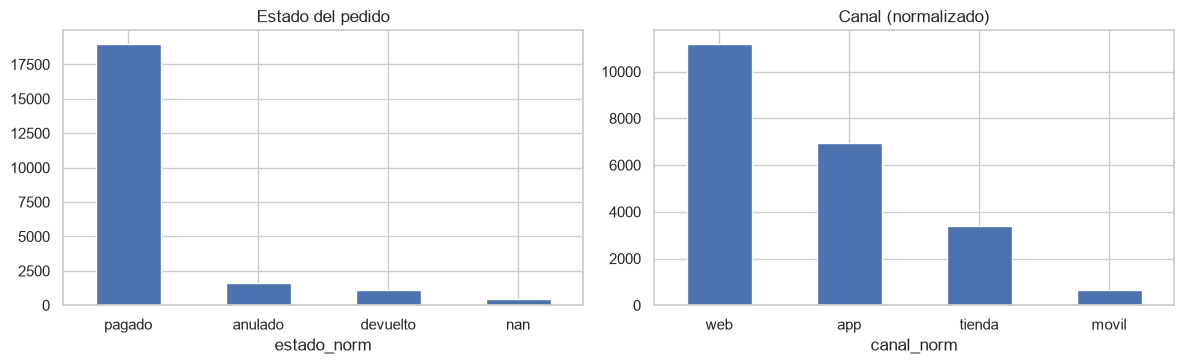

In [11]:
trx = transacciones.copy()
trx["sku"] = trx["sku"].astype("string").str.strip()
trx["usuario_id"] = trx["usuario_id"].astype("string").str.strip()

print(f"Duplicados exactos:                    {trx.duplicated().sum():,}")
print(f"Duplicados por (pedido_id, linea):     {trx.duplicated(['pedido_id', 'linea']).sum():,}")

# precio_unitario llega como texto en parte de las filas ("$22.743")
print(f"precio_unitario escrito como '$...': {trx['precio_unitario'].astype(str).str.startswith('$').sum():,}")
trx["precio_unitario"] = limpiar_monto(trx["precio_unitario"])

trx["estado_norm"] = norm_texto(trx["estado"]).replace({"-": np.nan})
trx["canal_norm"] = norm_texto(trx["canal"])
trx["fecha_dt"] = parse_fecha(trx["fecha"])

print(f"\nFechas no interpretables: {trx['fecha_dt'].isna().sum():,}")
print(f"Rango de fechas: {trx['fecha_dt'].min()}  →  {trx['fecha_dt'].max()}")
HOY = pd.Timestamp("2026-10-10")
print(f"Líneas con fecha posterior a hoy ({HOY.date()}): {(trx['fecha_dt'] > HOY).sum():,}  → fechas imposibles, se excluyen del modelado")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
trx["estado_norm"].value_counts(dropna=False).plot.bar(ax=ax[0], rot=0, title="Estado del pedido")
trx["canal_norm"].value_counts(dropna=False).plot.bar(ax=ax[1], rot=0, title="Canal (normalizado)")
plt.tight_layout(); plt.show()

In [12]:
# Coherencia de montos
trx["descuento_f"] = trx["descuento"].fillna(0)
trx["total_esperado"] = trx["cantidad"] * trx["precio_unitario"] - trx["descuento_f"]
trx["dif_total"] = trx["total"] - trx["total_esperado"]
con_precio = trx["precio_unitario"].notna()

chequeos = {
    "usuario_id nulo": int(trx["usuario_id"].isna().sum()),
    "usuario_id = 'invitado' (compra sin cuenta)": int((trx["usuario_id"].str.lower() == "invitado").sum()),
    "fecha futura": int((trx["fecha_dt"] > HOY).sum()),
    "precio_unitario nulo": int((~con_precio).sum()),
    "precio_unitario = 0": int((trx["precio_unitario"] == 0).sum()),
    "cantidad <= 0": int((trx["cantidad"] <= 0).sum()),
    "descuento nulo (se asume 0)": int(trx["descuento"].isna().sum()),
    "descuento > cantidad×precio": int((trx["descuento"] > trx["cantidad"] * trx["precio_unitario"]).sum()),
    "total ≠ cantidad×precio − descuento": int((con_precio & (trx["dif_total"].abs() > 1)).sum()),
    "total ≠ cantidad×precio (ignora descuento)": int((con_precio & ((trx["total"] - trx["cantidad"] * trx["precio_unitario"]).abs() > 1)).sum()),
}
pd.Series(chequeos, name="casos").to_frame().assign(**{"% de líneas": lambda d: d["casos"] / len(trx) * 100})

,casos,% de líneas
usuario_id nulo,93,0.42
usuario_id = 'invitado' (compra sin cuenta),94,0.42
fecha futura,15,0.07
precio_unitario nulo,440,1.98
precio_unitario = 0,0,0.00
cantidad <= 0,539,2.43
descuento nulo (se asume 0),8642,38.95
descuento > cantidad×precio,147,0.66
total ≠ cantidad×precio − descuento,2244,10.11
total ≠ cantidad×precio (ignora descuento),7865,35.45


Descripción de las diferencias de total (líneas con precio):


count       21,747.00
mean        11,332.49
std        253,069.16
min     -2,347,757.00
25%              0.00
50%              0.00
75%              0.00
max     16,099,920.00
Name: dif_total, dtype: Float64

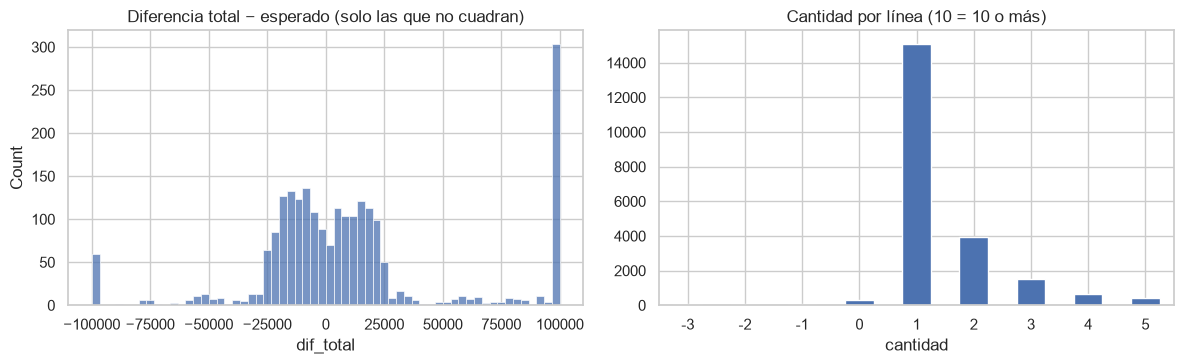

In [13]:
print("Descripción de las diferencias de total (líneas con precio):")
display(trx.loc[con_precio, "dif_total"].describe())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(trx.loc[con_precio & (trx["dif_total"].abs() > 1), "dif_total"].clip(-100000, 100000), bins=60, ax=ax[0])
ax[0].set_title("Diferencia total − esperado (solo las que no cuadran)")
trx["cantidad"].clip(upper=10).value_counts().sort_index().plot.bar(ax=ax[1], rot=0)
ax[1].set_title("Cantidad por línea (10 = 10 o más)")
plt.tight_layout(); plt.show()

### 3.3 Usuarios
Interesa en especial el **consentimiento** (`acepta_marketing`), porque el perfilamiento exige consentimiento explícito (Ley 21.719).

usuario_id duplicados: 26  |  filas duplicadas exactas: 26
Regiones distintas (crudo): 33  |  normalizado: 20
Fechas de registro no interpretables: 0
Edad nula: 139  |  fuera de 10–100: 155


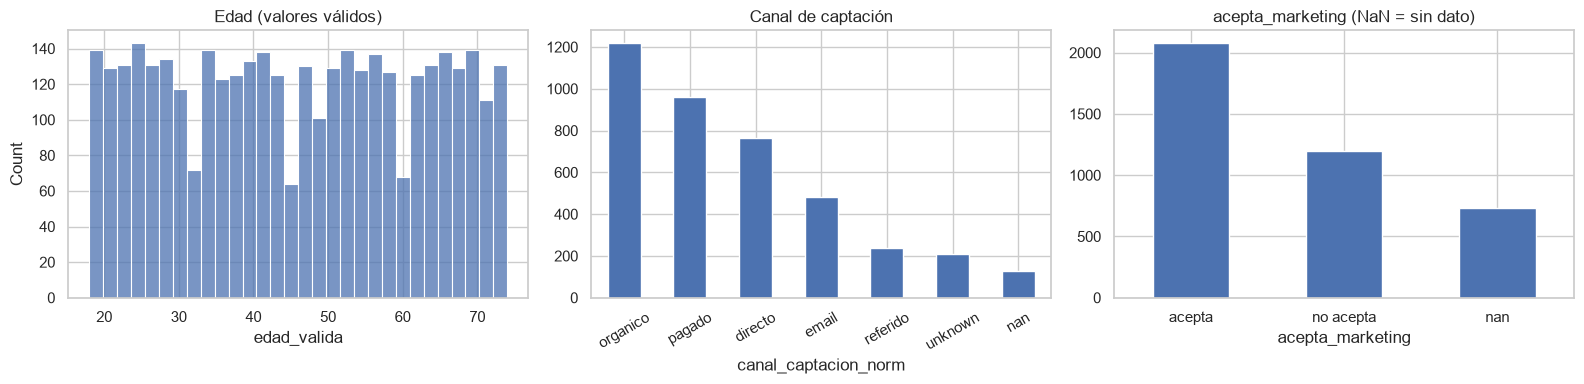

,usuarios
region_norm,
tarapaca,431
coquimbo,407
los lagos,386
antofagasta,378
valparaiso,292
araucania,280
maule,252
biobio,241
la araucania,139


In [14]:
usr = usuarios.copy()

print(f"usuario_id duplicados: {usr['usuario_id'].duplicated().sum()}  |  filas duplicadas exactas: {usr.duplicated().sum()}")
usr = usr.drop_duplicates().reset_index(drop=True)

usr["region_norm"] = norm_texto(usr["region"])
usr["comuna_norm"] = norm_texto(usr["comuna"])
usr["canal_captacion_norm"] = norm_texto(usr["canal_captacion"])
usr["fecha_registro_dt"] = parse_fecha(usr["fecha_registro"])
usr["edad_valida"] = usr["edad"].where(usr["edad"].between(10, 100))

print(f"Regiones distintas (crudo): {usr['region'].nunique()}  |  normalizado: {usr['region_norm'].nunique()}")
print(f"Fechas de registro no interpretables: {usr['fecha_registro_dt'].isna().sum()}")
print(f"Edad nula: {usr['edad'].isna().sum()}  |  fuera de 10–100: {(usr['edad'].notna() & usr['edad_valida'].isna()).sum()}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(usr["edad_valida"].dropna(), bins=30, ax=ax[0]); ax[0].set_title("Edad (valores válidos)")
usr["canal_captacion_norm"].value_counts(dropna=False).plot.bar(ax=ax[1], rot=30, title="Canal de captación")
usr["acepta_marketing"].value_counts(dropna=False).rename({1.0: "acepta", 0.0: "no acepta"}).plot.bar(ax=ax[2], rot=0, title="acepta_marketing (NaN = sin dato)")
plt.tight_layout(); plt.show()

display(usr["region_norm"].value_counts().head(20).to_frame("usuarios"))

In [15]:
print("Tabla de consentimiento y email válido:")
display(pd.crosstab(usr["acepta_marketing"].fillna(-1).map({1.0: "acepta", 0.0: "no acepta", -1.0: "sin dato"}),
                    usr["email_valido"].astype("string").fillna("sin dato"), margins=True))

Tabla de consentimiento y email válido:


email_valido,False,True,sin dato,All
acepta_marketing,,,,
acepta,183,1801,93,2077
no acepta,108,1031,55,1194
sin dato,56,642,31,729
All,347,3474,179,4000


### 3.4 Clickstream
Problemas esperados: sesiones repetidas entre usuarios distintos, robots sin marcar, eventos con nombres distintos, usuarios anónimos.

Duplicados exactos: 263  |  evento_id duplicados: 263
Timestamps no interpretables: 0  |  posteriores a hoy: 0
Rango: 2024-08-01 08:13:22  →  2026-08-01 00:35:55
Eventos sin usuario (anónimos): 17,653 (60.2%)


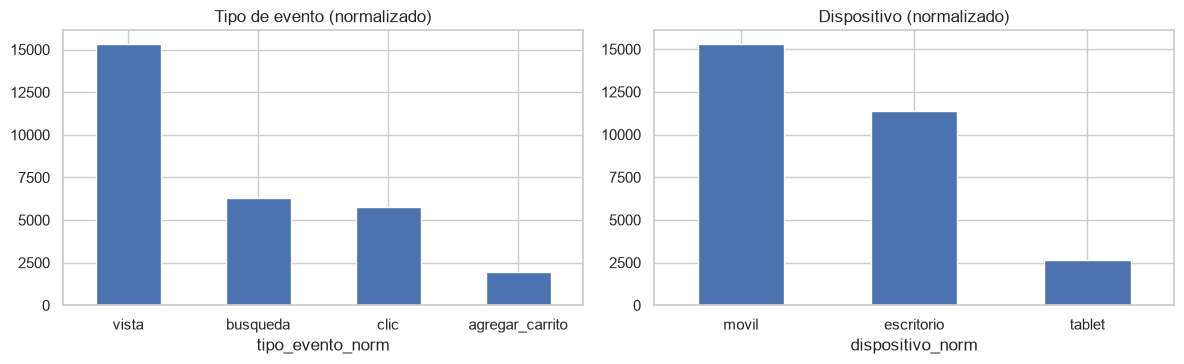

In [16]:
clk = clickstream.copy()
clk["sku"] = clk["sku"].astype("string").str.strip()
clk["usuario_id"] = clk["usuario_id"].astype("string").str.strip()

print(f"Duplicados exactos: {clk.duplicated().sum():,}  |  evento_id duplicados: {clk['evento_id'].duplicated().sum():,}")

mapa_evento = {"view": "vista", "click": "clic", "search": "busqueda", "add_to_cart": "agregar_carrito"}
clk["tipo_evento_norm"] = norm_texto(clk["tipo_evento"]).replace(mapa_evento)
mapa_disp = {"mobile": "movil", "desktop": "escritorio"}
clk["dispositivo_norm"] = norm_texto(clk["dispositivo"]).replace(mapa_disp)
clk["timestamp_dt"] = parse_fecha(clk["timestamp"])

print(f"Timestamps no interpretables: {clk['timestamp_dt'].isna().sum():,}  |  posteriores a hoy: {(clk['timestamp_dt'] > HOY).sum():,}")
print(f"Rango: {clk['timestamp_dt'].min()}  →  {clk['timestamp_dt'].max()}")
print(f"Eventos sin usuario (anónimos): {clk['usuario_id'].isna().sum():,} ({pct(clk['usuario_id'].isna().sum(), len(clk)):.1f}%)")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
clk["tipo_evento_norm"].value_counts().plot.bar(ax=ax[0], rot=0, title="Tipo de evento (normalizado)")
clk["dispositivo_norm"].value_counts().plot.bar(ax=ax[1], rot=0, title="Dispositivo (normalizado)")
plt.tight_layout(); plt.show()

In [17]:
# Robots: se detectan por user_agent
patron_bot = r"bot|crawl|spider|scrapy|curl|python-requests|wget|httpx|headless|slurp"
clk["es_bot"] = clk["user_agent"].fillna("").str.contains(patron_bot, case=False, regex=True)

print(f"Eventos de robots: {clk['es_bot'].sum():,} ({pct(clk['es_bot'].sum(), len(clk)):.1f}%)")
print(f"Sesiones con algún evento de robot: {clk.loc[clk['es_bot'], 'sesion_id'].nunique():,}")
print("\nUser agents marcados como robot:")
display(clk.loc[clk["es_bot"], "user_agent"].str.slice(0, 80).value_counts().to_frame("eventos"))

print("\nEventos de robots por tipo (¿inflan vistas?):")
display(pd.crosstab(clk["tipo_evento_norm"], clk["es_bot"]))

Eventos de robots: 1,791 (6.1%)
Sesiones con algún evento de robot: 144

User agents marcados como robot:


,eventos
user_agent,
Scrapy/2.11.0 (+https://scrapy.org),310
curl/8.4.0,302
Mozilla/5.0 (compatible; SemrushBot/7~bl; +http://www.semrush.com/bot.html),300
python-requests/2.31.0,299
Mozilla/5.0 (compatible; Googlebot/2.1; +http://www.google.com/bot.html),296
Mozilla/5.0 (compatible; AhrefsBot/7.0; +http://ahrefs.com/robot/),284



Eventos de robots por tipo (¿inflan vistas?):


es_bot,False,True
tipo_evento_norm,,
agregar_carrito,1925,0
busqueda,6289,0
clic,5773,0
vista,13562,1791


In [18]:
# Sesiones mal generadas: mismo sesion_id usado por usuarios distintos
usuarios_por_sesion = clk.dropna(subset=["usuario_id"]).groupby("sesion_id")["usuario_id"].nunique()
sesiones_mezcladas = usuarios_por_sesion[usuarios_por_sesion > 1]
print(f"Sesiones totales: {clk['sesion_id'].nunique():,}")
print(f"Sesiones compartidas por 2+ usuarios: {len(sesiones_mezcladas):,} ({pct(len(sesiones_mezcladas), clk['sesion_id'].nunique()):.1f}%)")

# Una sesión real no debería durar días: se mide el rango de tiempo por sesión
dur = clk.groupby("sesion_id")["timestamp_dt"].agg(lambda x: (x.max() - x.min()).total_seconds() / 3600)
print(f"Sesiones que abarcan más de 24 h: {(dur > 24).sum():,}")
print("\nEventos por sesión:")
display(clk.groupby("sesion_id").size().describe().to_frame("eventos"))

Sesiones totales: 6,000
Sesiones compartidas por 2+ usuarios: 284 (4.7%)
Sesiones que abarcan más de 24 h: 0

Eventos por sesión:


,eventos
count,"6,000.00"
mean,4.89
std,3.09
min,1.00
25%,2.00
50%,4.00
75%,7.00
max,19.00


In [19]:
# Búsquedas más frecuentes y completitud de sku según el tipo de evento
print("Términos de búsqueda más frecuentes:")
display(norm_texto(clk["termino_busqueda"]).value_counts().head(15).to_frame("búsquedas"))

print("\n% de eventos con sku, por tipo de evento:")
display(clk.groupby("tipo_evento_norm")["sku"].apply(lambda s: s.notna().mean() * 100).to_frame("% con sku"))

Términos de búsqueda más frecuentes:


,búsquedas
termino_busqueda,
mouse inalambrico,434
disco externo,423
iphone,420
router wifi 6,410
memoria ram ddr5,399
monitor 27,397
ssd 1tb,393
notebook gamer,392
silla gamer,386



% de eventos con sku, por tipo de evento:


,% con sku
tipo_evento_norm,
agregar_carrito,100.00
busqueda,0.00
clic,100.00
vista,100.00


## 4. Integridad entre datasets

In [20]:
skus_cat = set(prod["sku"])
usr_reg = set(usr["usuario_id"])

def cobertura(serie, universo, nombre):
    s = serie.dropna()
    ok = s.isin(universo)
    print(f"{nombre:55s} {ok.mean() * 100:6.1f}% de {len(s):,} registros existe en el catálogo/maestro")

cobertura(trx["sku"], skus_cat, "transacciones.sku  → productos.sku")
cobertura(clk["sku"], skus_cat, "clickstream.sku    → productos.sku")
cobertura(trx["usuario_id"], usr_reg, "transacciones.usuario_id → usuarios")
cobertura(clk["usuario_id"], usr_reg, "clickstream.usuario_id   → usuarios")

print("\nSKU de transacciones que NO están en el catálogo (top 5 por líneas):")
display(trx.loc[~trx["sku"].isin(skus_cat), "sku"].value_counts().head(5).to_frame("líneas"))

print("\nusuario_id de transacciones que NO están en usuarios (top 5 por líneas):")
display(trx.loc[trx["usuario_id"].notna() & ~trx["usuario_id"].isin(usr_reg), "usuario_id"].value_counts().head(5).to_frame("líneas"))

print("\nFormato de IDs que no sigue el patrón esperado (después de quitar espacios):")
print("  sku en productos (NX-#####):      ", (~prod["sku"].str.match(r"^NX-\d{5}$")).sum())
print("  sku en transacciones:             ", (~trx["sku"].str.match(r"^NX-\d{5}$", na=False)).sum())
print("  usuario_id en usuarios (U######): ", (~usr["usuario_id"].astype(str).str.match(r"^U\d{6}$")).sum())

transacciones.sku  → productos.sku                        97.1% de 22,187 registros existe en el catálogo/maestro
clickstream.sku    → productos.sku                       100.0% de 23,051 registros existe en el catálogo/maestro
transacciones.usuario_id → usuarios                       97.4% de 22,094 registros existe en el catálogo/maestro
clickstream.usuario_id   → usuarios                      100.0% de 11,687 registros existe en el catálogo/maestro

SKU de transacciones que NO están en el catálogo (top 5 por líneas):


,líneas
sku,
NX-90950,4
NX-99488,2
NX-94801,2
NX-99738,2
NX-94432,2



usuario_id de transacciones que NO están en usuarios (top 5 por líneas):


,líneas
usuario_id,
invitado,94
UNKNOWN,93
U972995,4
U993703,4
U983607,3



Formato de IDs que no sigue el patrón esperado (después de quitar espacios):
  sku en productos (NX-#####):       0
  sku en transacciones:              0
  usuario_id en usuarios (U######):  0


## 5. Análisis exploratorio sobre datos depurados
Se construye una vista depurada **en memoria** con reglas explícitas:

- Eliminar líneas duplicadas por `(pedido_id, linea)`.
- Conservar solo pedidos con estado `pagado` (se excluyen anulados, devueltos y el estado desconocido `-`).
- Excluir líneas sin `usuario_id` o de `invitado` (no hay a quién personalizar).
- Excluir líneas con cantidad ≤ 0 o con fecha posterior a hoy.
- Excluir eventos de clickstream de robots y con fecha imposible.

In [21]:
trx_ok = (
    trx.drop_duplicates(["pedido_id", "linea"])
       .query("estado_norm == 'pagado'")
       .dropna(subset=["usuario_id"])
       .query("usuario_id.str.lower() != 'invitado' and cantidad > 0 and fecha_dt <= @HOY")
       .copy()
)
clk_ok = clk.loc[~clk["es_bot"] & (clk["timestamp_dt"] <= HOY)].drop_duplicates("evento_id").copy()

embudo_limpieza = pd.Series({
    "transacciones originales": len(trx),
    "sin duplicados (pedido, línea)": len(trx.drop_duplicates(["pedido_id", "linea"])),
    "solo pagadas": int((trx.drop_duplicates(["pedido_id", "linea"])["estado_norm"] == "pagado").sum()),
    "con usuario, cantidad > 0 y fecha válida (base de modelado)": len(trx_ok),
    "clickstream original": len(clk),
    "clickstream sin robots, duplicados ni fechas imposibles": len(clk_ok),
}, name="filas")
embudo_limpieza.to_frame()

,filas
transacciones originales,22187
"sin duplicados (pedido, línea)",22001
solo pagadas,18857
"con usuario, cantidad > 0 y fecha válida (base de modelado)",18223
clickstream original,29340
"clickstream sin robots, duplicados ni fechas imposibles",27299


### 5.1 Evolución temporal de las ventas

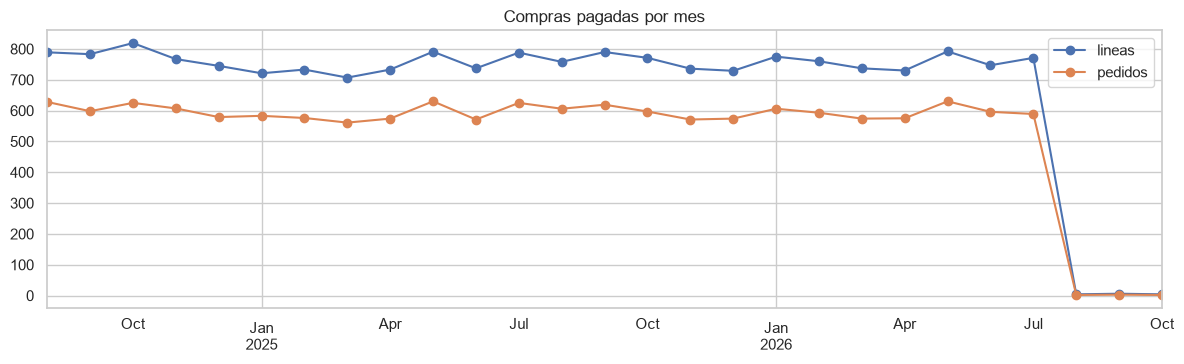

Período con compras: 2024-08-01 → 2026-10-10


In [22]:
mensual = (trx_ok.set_index("fecha_dt")
                 .resample("MS")
                 .agg(lineas=("pedido_id", "size"), pedidos=("pedido_id", "nunique"), unidades=("cantidad", "sum")))

fig, ax = plt.subplots(figsize=(12, 3.8))
mensual[["lineas", "pedidos"]].plot(ax=ax, marker="o")
ax.set_title("Compras pagadas por mes"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

print(f"Período con compras: {trx_ok['fecha_dt'].min().date()} → {trx_ok['fecha_dt'].max().date()}")

### 5.2 Tamaño del carrito (productos por pedido)

Pedidos: 14,294
Productos distintos por pedido (promedio): 1.27   (el caso reporta 1,3; meta 2,0)
Pedidos con 2+ productos distintos: 20.8%


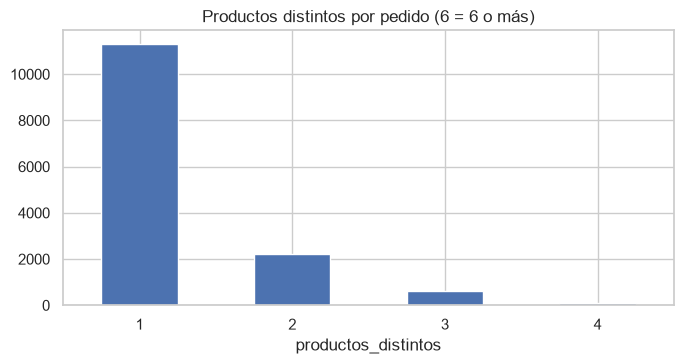

In [23]:
por_pedido = trx_ok.groupby("pedido_id").agg(productos_distintos=("sku", "nunique"), unidades=("cantidad", "sum"))
print(f"Pedidos: {len(por_pedido):,}")
print(f"Productos distintos por pedido (promedio): {por_pedido['productos_distintos'].mean():.2f}   (el caso reporta 1,3; meta 2,0)")
print(f"Pedidos con 2+ productos distintos: {pct((por_pedido['productos_distintos'] >= 2).sum(), len(por_pedido)):.1f}%")

fig, ax = plt.subplots(figsize=(7, 3.8))
por_pedido["productos_distintos"].clip(upper=6).value_counts().sort_index().plot.bar(ax=ax, rot=0)
ax.set_title("Productos distintos por pedido (6 = 6 o más)")
plt.tight_layout(); plt.show()

### 5.3 Concentración de ventas y cola larga

SKU únicos del catálogo (muestra): 1,500
SKU del catálogo con al menos una compra: 570 (38.0%)
SKU del catálogo sin ninguna compra en la muestra: 930 (62.0%)  (el caso reporta 62% a nivel de catálogo completo)
SKU con compras que NO existen en el catálogo: 517 → ['NX-90033', 'NX-90051', 'NX-90059', 'NX-90062', 'NX-90083']
SKU que concentran el 80% de las unidades: 82 (7.5% de los SKU vendidos)


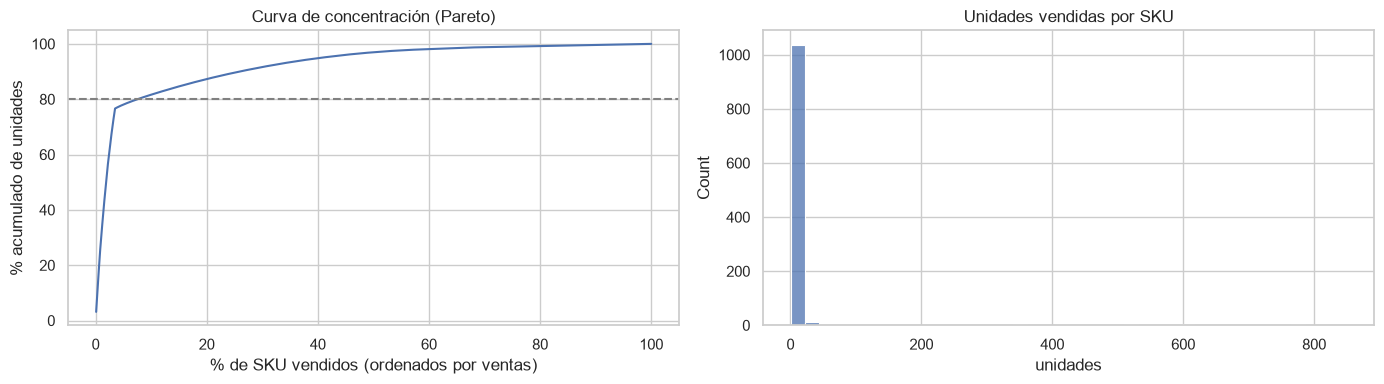

In [24]:
ventas_sku = trx_ok.groupby("sku")["cantidad"].sum().sort_values(ascending=False)
acum = ventas_sku.cumsum() / ventas_sku.sum()
n80 = int((acum <= 0.80).sum() + 1)

skus_vendidos = set(ventas_sku.index)
skus_vendidos_en_catalogo = skus_vendidos & set(prod["sku"])
nunca = prod.loc[~prod["sku"].isin(skus_vendidos)]
huerfanos = skus_vendidos - set(prod["sku"])

print(f"SKU únicos del catálogo (muestra): {len(prod):,}")
print(f"SKU del catálogo con al menos una compra: {len(skus_vendidos_en_catalogo):,} ({pct(len(skus_vendidos_en_catalogo), len(prod)):.1f}%)")
print(f"SKU del catálogo sin ninguna compra en la muestra: {len(nunca):,} ({pct(len(nunca), len(prod)):.1f}%)  (el caso reporta 62% a nivel de catálogo completo)")
print(f"SKU con compras que NO existen en el catálogo: {len(huerfanos):,} → {sorted(huerfanos)[:5]}")
print(f"SKU que concentran el 80% de las unidades: {n80:,} ({pct(n80, len(ventas_sku)):.1f}% de los SKU vendidos)")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(np.arange(1, len(acum) + 1) / len(acum) * 100, acum.values * 100)
ax[0].axhline(80, ls="--", c="gray"); ax[0].set_xlabel("% de SKU vendidos (ordenados por ventas)"); ax[0].set_ylabel("% acumulado de unidades")
ax[0].set_title("Curva de concentración (Pareto)")
sns.histplot(ventas_sku, bins=40, ax=ax[1]); ax[1].set_title("Unidades vendidas por SKU"); ax[1].set_xlabel("unidades")
plt.tight_layout(); plt.show()

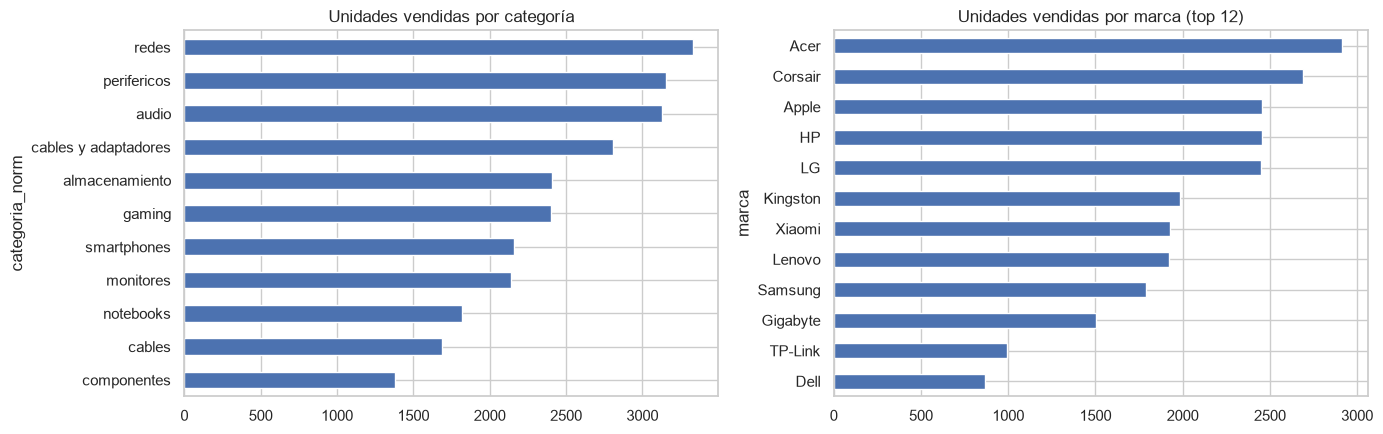

Compras de productos hoy inactivos o sin stock (relevante para RF5):
  líneas de SKU inactivos: 6,189
  líneas de SKU con stock <= 0 hoy: 4,730


In [25]:
trx_cat = trx_ok.merge(prod[["sku", "categoria_norm", "marca", "precio_lista"]], on="sku", how="left")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
trx_cat.groupby("categoria_norm")["cantidad"].sum().sort_values().tail(12).plot.barh(ax=ax[0])
ax[0].set_title("Unidades vendidas por categoría")
trx_cat.groupby("marca")["cantidad"].sum().sort_values().tail(12).plot.barh(ax=ax[1])
ax[1].set_title("Unidades vendidas por marca (top 12)")
plt.tight_layout(); plt.show()

print("Compras de productos hoy inactivos o sin stock (relevante para RF5):")
estado_prod = trx_cat.merge(prod[["sku", "activo_bool", "stock"]], on="sku", how="left")
print(f"  líneas de SKU inactivos: {(estado_prod['activo_bool'] == False).sum():,}")
print(f"  líneas de SKU con stock <= 0 hoy: {(estado_prod['stock'] <= 0).sum():,}")

### 5.4 Comportamiento de los usuarios

Usuarios con al menos una compra pagada: 4,095
Usuarios con 2+ pedidos:  3,436 (83.9%)
Usuarios con 3+ pedidos:  2,713 (66.3%)
Usuarios que compraron una sola vez: 16.1%  (el caso reporta 71% a 24 meses)


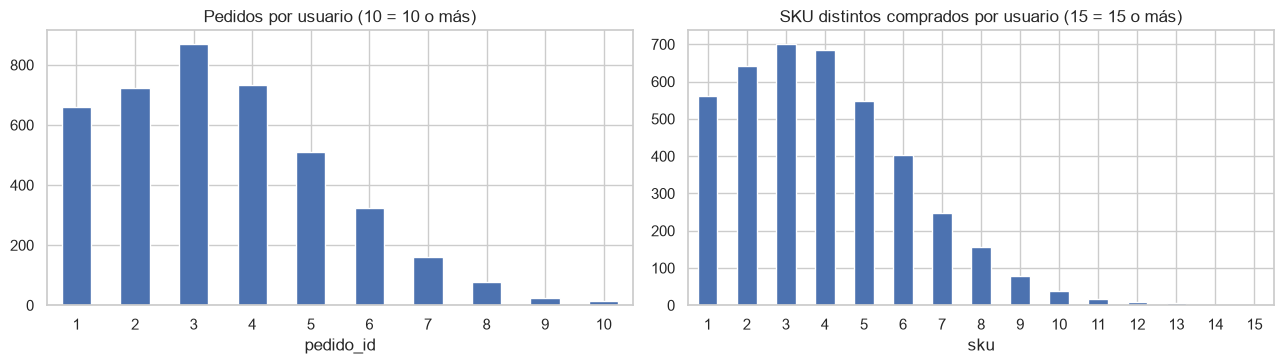


Pares usuario–SKU únicos: 16,361
Densidad de la matriz usuario × SKU: 0.3676%  (dispersión: 99.6324%)


In [26]:
pedidos_usuario = trx_ok.groupby("usuario_id")["pedido_id"].nunique()
skus_usuario = trx_ok.groupby("usuario_id")["sku"].nunique()

print(f"Usuarios con al menos una compra pagada: {len(pedidos_usuario):,}")
print(f"Usuarios con 2+ pedidos:  {(pedidos_usuario >= 2).sum():,} ({pct((pedidos_usuario >= 2).sum(), len(pedidos_usuario)):.1f}%)")
print(f"Usuarios con 3+ pedidos:  {(pedidos_usuario >= 3).sum():,} ({pct((pedidos_usuario >= 3).sum(), len(pedidos_usuario)):.1f}%)")
print(f"Usuarios que compraron una sola vez: {pct((pedidos_usuario == 1).sum(), len(pedidos_usuario)):.1f}%  (el caso reporta 71% a 24 meses)")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
pedidos_usuario.clip(upper=10).value_counts().sort_index().plot.bar(ax=ax[0], rot=0)
ax[0].set_title("Pedidos por usuario (10 = 10 o más)")
skus_usuario.clip(upper=15).value_counts().sort_index().plot.bar(ax=ax[1], rot=0)
ax[1].set_title("SKU distintos comprados por usuario (15 = 15 o más)")
plt.tight_layout(); plt.show()

# Dispersión de la matriz usuario × SKU
pares = trx_ok[["usuario_id", "sku"]].drop_duplicates()
densidad = len(pares) / (trx_ok["usuario_id"].nunique() * trx_ok["sku"].nunique())
print(f"\nPares usuario–SKU únicos: {len(pares):,}")
print(f"Densidad de la matriz usuario × SKU: {densidad * 100:.4f}%  (dispersión: {100 - densidad * 100:.4f}%)")

### 5.5 Clickstream: embudo e interés implícito

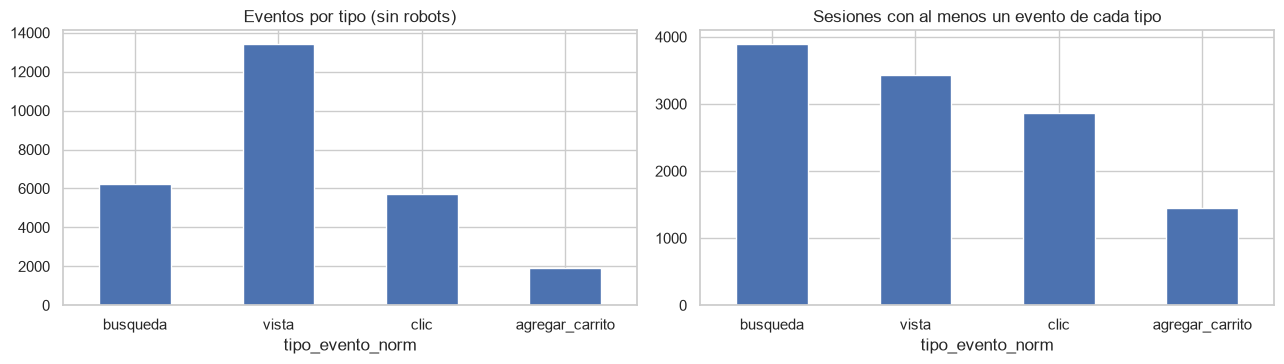

Sesiones sin ninguna vista de producto: 41.4%  (el caso reporta 41%)
Nota: el clickstream no trae un evento de 'compra'; la compra solo se observa en transacciones.


In [27]:
orden = ["busqueda", "vista", "clic", "agregar_carrito"]
eventos = clk_ok["tipo_evento_norm"].value_counts().reindex(orden)
sesiones_evento = clk_ok.groupby("tipo_evento_norm")["sesion_id"].nunique().reindex(orden)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
eventos.plot.bar(ax=ax[0], rot=0, title="Eventos por tipo (sin robots)")
sesiones_evento.plot.bar(ax=ax[1], rot=0, title="Sesiones con al menos un evento de cada tipo")
plt.tight_layout(); plt.show()

n_ses = clk_ok["sesion_id"].nunique()
sin_ficha = n_ses - clk_ok.loc[clk_ok["tipo_evento_norm"] == "vista", "sesion_id"].nunique()
print(f"Sesiones sin ninguna vista de producto: {pct(sin_ficha, n_ses):.1f}%  (el caso reporta 41%)")
print("Nota: el clickstream no trae un evento de 'compra'; la compra solo se observa en transacciones.")

In [28]:
# Cuánto del clickstream sirve para personalizar (usuario identificado + sku)
util = clk_ok[clk_ok["usuario_id"].notna() & clk_ok["sku"].notna()]
print(f"Eventos con usuario y sku (sin robots): {len(util):,} de {len(clk_ok):,} ({pct(len(util), len(clk_ok)):.1f}%)")
print(f"Usuarios identificados distintos en clickstream: {util['usuario_id'].nunique():,}")

# Interacciones por tipo para el puntaje de interés implícito
display(pd.crosstab(util["tipo_evento_norm"], util["usuario_id"].notna()).rename(columns={True: "eventos"}))

print("\nProductos más vistos (top 10) vs. más comprados (top 10):")
top_vistos = clk_ok.loc[clk_ok["tipo_evento_norm"] == "vista", "sku"].value_counts().head(10)
top_comprados = ventas_sku.head(10)
display(pd.DataFrame({"más vistos": top_vistos.index, "vistas": top_vistos.values,
                      "más comprados": top_comprados.index, "unidades": top_comprados.values}))

Eventos con usuario y sku (sin robots): 8,938 de 27,299 (32.7%)
Usuarios identificados distintos en clickstream: 1,857


usuario_id,eventos
tipo_evento_norm,
agregar_carrito,792
clic,2435
vista,5711



Productos más vistos (top 10) vs. más comprados (top 10):


,más vistos,vistas,más comprados,unidades
0,NX-11373,334,NX-10972,849
1,NX-10191,311,NX-11331,826
2,NX-11040,308,NX-11373,795
3,NX-11142,303,NX-11144,782
4,NX-10899,296,NX-11359,776
5,NX-11410,295,NX-11408,773
6,NX-11438,292,NX-10622,754
7,NX-10622,292,NX-10722,753
8,NX-10051,290,NX-10979,697
9,NX-10464,289,NX-10899,646


## 6. Viabilidad de la variable objetivo
La variable objetivo es `compra(usuario, sku)`. Para validarla sin filtrar el futuro hace falta un **corte temporal**: se entrena con lo anterior a una fecha y se evalúa con lo posterior. Aquí se verifica cuántos usuarios y compras quedarían disponibles en cada lado.

In [29]:
fechas = trx_ok["fecha_dt"]
filas = []
for q in [0.6, 0.7, 0.8, 0.9]:
    corte = fechas.quantile(q)
    antes = trx_ok[trx_ok["fecha_dt"] < corte]
    despues = trx_ok[trx_ok["fecha_dt"] >= corte]
    u_antes = set(antes["usuario_id"])
    u_despues = set(despues["usuario_id"])
    comunes = u_antes & u_despues
    despues_conocidos = despues[despues["usuario_id"].isin(u_antes)]
    pares_antes = set(zip(antes["usuario_id"], antes["sku"]))
    recompras = sum((u, s) in pares_antes for u, s in zip(despues_conocidos["usuario_id"], despues_conocidos["sku"]))
    filas.append({
        "corte": corte.date(),
        "líneas train": len(antes),
        "líneas test": len(despues),
        "usuarios train": len(u_antes),
        "usuarios test": len(u_despues),
        "usuarios en ambos (evaluables)": len(comunes),
        "% usuarios test con historial": pct(len(comunes), len(u_despues)),
        "líneas test de usuarios con historial": len(despues_conocidos),
        "% de esas que son recompra del mismo SKU": pct(recompras, len(despues_conocidos)),
    })
pd.DataFrame(filas).set_index("corte")

,líneas train,líneas test,usuarios train,usuarios test,usuarios en ambos (evaluables),% usuarios test con historial,líneas test de usuarios con historial,% de esas que son recompra del mismo SKU
corte,,,,,,,,
2025-10-11,10934,7289,3647,3072,2624,85.42,6313,13.23
2025-12-26,12756,5467,3811,2652,2368,89.29,4926,14.84
2026-03-07,14578,3645,3932,2054,1891,92.06,3391,15.25
2026-05-20,16399,1824,4020,1203,1128,93.77,1716,17.72


In [30]:
# Frecuencia de recompra y arranque en frío
corte = fechas.quantile(0.8)
test = trx_ok[trx_ok["fecha_dt"] >= corte]
u_hist = set(trx_ok.loc[trx_ok["fecha_dt"] < corte, "usuario_id"])
sku_hist = set(trx_ok.loc[trx_ok["fecha_dt"] < corte, "sku"])

print(f"Corte usado: {corte.date()}")
print(f"Compras en test de usuarios SIN historial previo (arranque en frío de usuario): {pct((~test['usuario_id'].isin(u_hist)).sum(), len(test)):.1f}%")
print(f"Compras en test de SKU SIN ventas previas (arranque en frío de producto):      {pct((~test['sku'].isin(sku_hist)).sum(), len(test)):.1f}%")

# Usuarios con clickstream identificado que no tienen compras: oportunidad para la señal implícita
u_click = set(util["usuario_id"])
u_compra = set(trx_ok["usuario_id"])
print(f"\nUsuarios con clickstream identificado: {len(u_click):,}")
print(f"  de ellos con compras: {len(u_click & u_compra):,}")
print(f"  de ellos SIN compras (solo se pueden modelar con señal implícita): {len(u_click - u_compra):,}")

Corte usado: 2026-03-07
Compras en test de usuarios SIN historial previo (arranque en frío de usuario): 7.0%
Compras en test de SKU SIN ventas previas (arranque en frío de producto):      3.1%

Usuarios con clickstream identificado: 1,857
  de ellos con compras: 1,781
  de ellos SIN compras (solo se pueden modelar con señal implícita): 76


## 7. Resumen y decisiones para el modelado

In [31]:
resumen_final = pd.Series({
    "Líneas de transacción originales": len(trx),
    "Líneas duplicadas (pedido, línea)": int(trx.duplicated(["pedido_id", "linea"]).sum()),
    "Líneas válidas (base de modelado)": len(trx_ok),
    "Usuarios con compra": trx_ok["usuario_id"].nunique(),
    "Usuarios con 2+ pedidos": int((pedidos_usuario >= 2).sum()),
    "SKU con compra (en catálogo)": len(skus_vendidos_en_catalogo),
    "SKU con compra que no están en el catálogo": len(huerfanos),
    "SKU sin compra en la muestra": len(nunca),
    "Densidad matriz usuario×SKU (%)": densidad * 100,
    "Eventos de clickstream de robots": int(clk["es_bot"].sum()),
    "Sesiones compartidas por 2+ usuarios": len(sesiones_mezcladas),
    "Eventos anónimos en clickstream (%)": pct(clk["usuario_id"].isna().sum(), len(clk)),
    "Usuarios sin dato de consentimiento": int(usr["acepta_marketing"].isna().sum()),
}, name="valor")
resumen_final.to_frame()

,valor
Líneas de transacción originales,"22,187.00"
"Líneas duplicadas (pedido, línea)",186.00
Líneas válidas (base de modelado),"18,223.00"
Usuarios con compra,"4,095.00"
Usuarios con 2+ pedidos,"3,436.00"
SKU con compra (en catálogo),570.00
SKU con compra que no están en el catálogo,517.00
SKU sin compra en la muestra,930.00
Densidad matriz usuario×SKU (%),0.37
Eventos de clickstream de robots,"1,791.00"


### Decisiones de limpieza a aplicar en el siguiente notebook

| Dataset | Problema detectado | Decisión |
|---|---|---|
| productos | Categorías con distinta capitalización, tildes y espacios | Normalizar (minúsculas, sin tildes) |
| productos | `activo` con valores `Si/No/true/false/0/1` | Convertir a booleano |
| productos | Precio 0 o nulo, stock negativo | Marcar como no recomendable; no usar precio 0 como feature |
| transacciones | Líneas duplicadas por reproceso | Eliminar por `(pedido_id, linea)` |
| transacciones | Estados `anulado`, `devuelto`, `-` | Usar solo `pagado` para la variable objetivo |
| transacciones | `total` no cuadra con cantidad × precio − descuento | No usar `total` como predictor ni como objetivo |
| transacciones | `usuario_id` nulo o `invitado` | Excluir de modelos personalizados |
| transacciones | Cantidad ≤ 0 y fechas posteriores a hoy | Excluir |
| transacciones | `precio_unitario` como texto (`$22.743`) | Convertir a número (punto = miles) |
| transacciones | SKU que no existen en el catálogo | Revisar con el equipo; excluir del modelo hasta aclarar |
| productos | SKU con espacios, filas duplicadas, `stock = ERROR` | Limpiar espacios, eliminar duplicados, tratar `ERROR` como stock desconocido |
| usuarios | Edad inválida, región con variantes, fechas mixtas | Anular edades fuera de rango; normalizar texto; parsear fechas |
| usuarios | `acepta_marketing` nulo o 0 | Tratar nulo como sin consentimiento hasta que cumplimiento decida lo contrario |
| clickstream | Robots sin marcar | Filtrar por `user_agent` |
| clickstream | `sesion_id` compartido entre usuarios | No confiar en `sesion_id` para métricas; preferir `usuario_id` |
| clickstream | Eventos con nombres distintos | Mapear a `vista`, `clic`, `busqueda`, `agregar_carrito` |
| clickstream | Eventos anónimos | Usar solo para modelos de sesión o de contenido, no para personalización por usuario |

### Próximo paso
`02_preparacion_datos.ipynb`: aplicar estas reglas, construir la variable objetivo `compra` con corte temporal y generar el conjunto de entrenamiento y evaluación.